
# 🧬 TASK A — Sperm vs Non-Sperm (Binary Classification)

**Dataset:** *Expert-Annotated Optical Microscopy Images of Human Sperm for Detection and DNA Fragmentation Assessment* (Saadat, Borna & Torkashvand, Scientific Data 2026) — Figshare DOI: `10.6084/m9.figshare.30120811`

Notebook này huấn luyện & so sánh các **teacher model** cho bài toán phân loại nhị phân **Sperm / Non-Sperm** trên các patch ảnh đã được crop sẵn (650 ảnh: 320 Sperm, 330 Non-Sperm).

**Các model benchmark trong notebook này:** `resnet50`, `convnext_base`

### Quyết định thiết kế đã chốt
| Vấn đề | Quyết định |
|---|---|
| Chia dữ liệu | Hold-out cố định **70/15/15** (stratified theo lớp), chia **một lần duy nhất**, lưu vào `data/taskA_split.json` trên Drive — mọi lần chạy sau (kể cả notebook Evaluation) đều load lại đúng file này để **không rò rỉ tập test** |
| Preprocessing | Dữ liệu đã là các patch crop sẵn → **không cần** bước tiền xử lý nặng; chỉ resize/normalize theo từng model + augmentation nhẹ khi train |
| Fine-tuning | **2-Stage**: Stage 1 đóng băng backbone, chỉ train classifier head → Stage 2 mở toàn bộ, fine-tune với learning rate rất nhỏ cho backbone (discriminative LR) |
| Early Stopping | Theo dõi **Macro-F1 trên tập validation** (phù hợp hơn Accuracy khi có thể mất cân bằng lớp nhẹ) |
| Idempotency | Mọi bước tải dữ liệu / giải nén / chia tập đều tự kiểm tra tồn tại trước khi làm lại — an toàn khi chạy ngắt quãng nhiều ngày hoặc train nhiều model song song trong cùng phiên Colab |

⚠️ **Lưu ý quan trọng:** Notebook này **CHỈ dùng tập train + val**. Tập test được giữ hoàn toàn tách biệt và chỉ được dùng trong notebook `Evaluation.ipynb` để đảm bảo đánh giá không thiên vị (unbiased).


## 1. Cài đặt thư viện

In [1]:

!pip install -q timm==1.0.11 scikit-learn seaborn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 90.8 MB/s eta 0:00:00


## 2. Import & thiết lập seed / device

In [2]:

import os, sys, json, time, random, shutil, zipfile, glob, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
from timm.data import resolve_data_config
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, confusion_matrix, classification_report)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Thiết bị đang sử dụng: cuda
GPU: Tesla T4


## 3. Kết nối Google Drive & định nghĩa đường dẫn

In [3]:

from google.colab import drive
drive.mount('/content/drive')

# ==== ĐƯỜNG DẪN GỐC TRÊN DRIVE (chỉnh nếu bạn muốn đổi vị trí lưu) ====
DRIVE_ROOT       = "/content/drive/MyDrive/SpermAI_Benchmark"
DATA_DRIVE_DIR   = f"{DRIVE_ROOT}/data"            # cache zip gốc + file chia tập cố định (dùng chung cho cả Task A & B)
OUTPUT_DRIVE_DIR = f"{DRIVE_ROOT}/outputs/TaskA"   # kết quả (model, log, hình...) của TỪNG model trong Task A
os.makedirs(DATA_DRIVE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DRIVE_DIR, exist_ok=True)

# ==== ĐƯỜNG DẪN LÀM VIỆC TRÊN COLAB (local, đọc/ghi nhanh hơn Drive rất nhiều) ====
LOCAL_ROOT   = "/content/sperm_data"
RAW_ROOT     = f"{LOCAL_ROOT}/raw_extracted"
RAW_ZIP_PATH = f"{LOCAL_ROOT}/dataset_download.zip"
os.makedirs(LOCAL_ROOT, exist_ok=True)

print("DATA_DRIVE_DIR  :", DATA_DRIVE_DIR)
print("OUTPUT_DRIVE_DIR:", OUTPUT_DRIVE_DIR)


Mounted at /content/drive
DATA_DRIVE_DIR  : /content/drive/MyDrive/SpermAI_Benchmark/data
OUTPUT_DRIVE_DIR: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA



## 4. Tải & giải nén dataset (idempotent)

Thứ tự ưu tiên:
1. Nếu dữ liệu **đã tồn tại sẵn trong `/content`** (ví dụ bạn vừa train xong 1 model và đang chuyển sang model tiếp theo trong cùng phiên Colab) → **bỏ qua hoàn toàn**, dùng chung luôn.
2. Nếu chưa có → thử tải trực tiếp từ **Figshare**.
3. Nếu Figshare lỗi (mạng, đổi link,...) → dùng bản **cache zip trên Google Drive** (nếu đã từng tải thành công trước đó, hoặc bạn tự upload thủ công).
4. Sau khi tải/giải nén thành công lần đầu → tự động sao lưu zip gốc lên Drive để các phiên sau không cần tải lại từ Figshare.


In [4]:
import subprocess

FIGSHARE_ARTICLE_ID   = "30120811"
FIGSHARE_DOWNLOAD_URL = f"https://ndownloader.figshare.com/articles/{FIGSHARE_ARTICLE_ID}/versions/1"
DRIVE_CACHED_ZIP      = f"{DATA_DRIVE_DIR}/figshare_raw_dataset.zip"

def _find_dir(root, keyword):
    """Tìm (đệ quy) thư mục có tên chứa `keyword` (không phân biệt hoa/thường)."""
    keyword = keyword.lower()
    for dirpath, dirnames, _ in os.walk(root):
        for d in dirnames:
            if keyword in d.lower():
                return os.path.join(dirpath, d)
    return None

def _extract_recursive(zip_path, dest):
    """Giải nén archive Figshare bằng unrar.
    File Figshare có thể mang đuôi .zip nhưng thực tế chứa archive RAR
    (bên trong có Dataset/ và các thư mục dữ liệu thật)."""
    result = subprocess.run(
        ["unrar", "x", "-o+", "-p-", zip_path, dest + "/"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Giải nén archive thất bại.")

def dataset_is_ready(root):
    """Dữ liệu thô được coi là sẵn sàng khi tìm thấy cả 2 thư mục nhãn gốc."""
    bin_dir  = _find_dir(root, "Binary Classification")
    halo_dir = _find_dir(root, "Halo Classification")
    ok = bool(bin_dir) and bool(halo_dir)
    if ok:
        print(f"  ✓ Tìm thấy: {bin_dir}")
        print(f"  ✓ Tìm thấy: {halo_dir}")
    return ok

if dataset_is_ready(RAW_ROOT):
    # ƯU TIÊN 1: dữ liệu đã có sẵn trong phần cứng Colab (phiên hiện tại) -> dùng chung, không tải lại
    print("✅ Dữ liệu thô đã có sẵn trong phần cứng Colab (phiên hiện tại) — bỏ qua tải & giải nén (dùng chung giữa các model).")
else:
    os.makedirs(RAW_ROOT, exist_ok=True)
    downloaded = False

    # ƯU TIÊN 2: đã có bản zip cache trên Google Drive (từ lần chạy trước, tự động HOẶC bạn tự upload thủ công)
    if os.path.exists(DRIVE_CACHED_ZIP):
        print("⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).")
        shutil.copy(DRIVE_CACHED_ZIP, RAW_ZIP_PATH)
        downloaded = True
    else:
        # ƯU TIÊN 3 (chỉ xảy ra ở LẦN CHẠY ĐẦU TIÊN, khi Drive chưa có gì): tải từ Figshare
        print("⬇️  Chưa có bản cache trên Drive — đang tải dataset từ Figshare (chỉ xảy ra ở lần đầu tiên) ...")
        try:
            import urllib.request
            urllib.request.urlretrieve(FIGSHARE_DOWNLOAD_URL, RAW_ZIP_PATH)
            if os.path.getsize(RAW_ZIP_PATH) > 10_000:
                downloaded = True
        except Exception as e:
            print(f"  ✗ Tải từ Figshare thất bại: {e}")

    if not downloaded:
        raise RuntimeError(
            "Không thể tải dataset tự động (không có cache trên Drive, và tải từ Figshare thất bại).\n"
            "→ Hãy tải thủ công file zip tại https://doi.org/10.6084/m9.figshare.30120811,\n"
            f"  upload lên Google Drive đúng đường dẫn: {DRIVE_CACHED_ZIP}\n"
            "  rồi chạy lại cell này."
        )

    print("📦 Đang giải nén ...")
    _extract_recursive(RAW_ZIP_PATH, RAW_ROOT)

    if not dataset_is_ready(RAW_ROOT):
        raise RuntimeError(
            "Giải nén xong nhưng KHÔNG tìm thấy thư mục 'Binary Classification' hoặc 'Halo Classification'.\n"
            "→ Hãy kiểm tra thủ công cấu trúc bên trong RAW_ROOT (dùng lệnh !find) và chỉnh lại hàm _find_dir nếu tên khác."
        )

    # Nếu zip này vừa được tải MỚI từ Figshare (Drive lúc nãy chưa có) -> tự backup lên Drive cho các lần sau.
    # Nếu bạn muốn tự kiểm soát bản cache (tự nén thủ công), chỉ cần upload file của bạn đúng path
    # DRIVE_CACHED_ZIP trước khi chạy cell này — code sẽ ưu tiên dùng bản đó và bỏ qua bước tải Figshare.
    if not os.path.exists(DRIVE_CACHED_ZIP):
        print("☁️  Sao lưu zip gốc lên Drive để các lần chạy sau không cần tải lại từ Figshare ...")
        shutil.copy(RAW_ZIP_PATH, DRIVE_CACHED_ZIP)

    print("✅ Hoàn tất tải & giải nén dataset.")

BINARY_DIR = _find_dir(RAW_ROOT, "Binary Classification")
HALO_DIR   = _find_dir(RAW_ROOT, "Halo Classification")   # không dùng ở Task A, chỉ in ra để kiểm tra
print("\nBINARY_DIR:", BINARY_DIR)
print("HALO_DIR  :", HALO_DIR, " (không dùng trong Task A)")

⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).
📦 Đang giải nén ...
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Binary Classification
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Halo Classification
✅ Hoàn tất tải & giải nén dataset.

BINARY_DIR: /content/sperm_data/raw_extracted/Dataset/Binary Classification
HALO_DIR  : /content/sperm_data/raw_extracted/Dataset/Halo Classification  (không dùng trong Task A)



## 5. Phát hiện danh sách lớp & liệt kê toàn bộ ảnh

⚠️ Bài báo mô tả 650 ảnh (320 Sperm / 330 NonSperm) trong 2 thư mục con `Sperm` và `NonSperm`, nhưng để an toàn, ta **tự động dò tên thư mục con thực tế** thay vì hard-code — tránh lỗi nếu tên thư mục trên Figshare khác nhẹ so với văn bản trong bài báo.


In [5]:

TASK_RAW_DIR = BINARY_DIR
assert TASK_RAW_DIR is not None, "Không tìm thấy thư mục dữ liệu Task A!"

CLASSES = sorted([d for d in os.listdir(TASK_RAW_DIR) if os.path.isdir(os.path.join(TASK_RAW_DIR, d))])
print(f"Phát hiện {len(CLASSES)} lớp: {CLASSES}")

IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
samples = []
for cls in CLASSES:
    cls_dir = os.path.join(TASK_RAW_DIR, cls)
    files = sorted([f for f in os.listdir(cls_dir) if f.lower().endswith(IMG_EXTS)])
    for f in files:
        samples.append({"class": cls, "filename": f, "path": os.path.join(cls_dir, f)})

df_samples = pd.DataFrame(samples)
print("\nTổng số ảnh mỗi lớp:")
print(df_samples.groupby("class").size())
assert len(df_samples) > 0, "Không đọc được ảnh nào — kiểm tra lại đường dẫn TASK_RAW_DIR."

class_to_idx = {c: i for i, c in enumerate(CLASSES)}
print("\nclass_to_idx:", class_to_idx)


Phát hiện 2 lớp: ['Non-sperm', 'Sperm']

Tổng số ảnh mỗi lớp:
class
Non-sperm    330
Sperm        320
dtype: int64

class_to_idx: {'Non-sperm': 0, 'Sperm': 1}



## 6. Chia train / val / test cố định (70/15/15, stratified)

File `taskA_split.json` chỉ được **tạo đúng 1 lần** rồi lưu lên Drive. Mọi lần chạy sau — dù là model khác, ngày khác, hay notebook Evaluation — đều **load lại chính file này**, đảm bảo:
- Không có ảnh nào vô tình lọt từ tập train/val sang test giữa các lần chạy khác nhau.
- Tất cả model được so sánh công bằng trên đúng cùng 1 tập test.


In [6]:

SPLIT_JSON_DRIVE = f"{DATA_DRIVE_DIR}/taskA_split.json"
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

if os.path.exists(SPLIT_JSON_DRIVE):
    print("📄 Đã có file chia tập trên Drive → dùng lại (đảm bảo nhất quán giữa các lần chạy).")
    with open(SPLIT_JSON_DRIVE, "r") as f:
        split_map = json.load(f)
else:
    print("✂️  Chưa có file chia tập → tạo mới (CHỈ diễn ra 1 LẦN DUY NHẤT cho toàn bộ benchmark Task A).")
    train_val, test = train_test_split(
        df_samples, test_size=TEST_RATIO, stratify=df_samples["class"], random_state=SEED
    )
    val_ratio_adj = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
    train, val = train_test_split(
        train_val, test_size=val_ratio_adj, stratify=train_val["class"], random_state=SEED
    )
    split_map = {
        "train": train[["class", "filename"]].values.tolist(),
        "val":   val[["class", "filename"]].values.tolist(),
        "test":  test[["class", "filename"]].values.tolist(),
    }
    with open(SPLIT_JSON_DRIVE, "w") as f:
        json.dump(split_map, f, indent=2)
    print(f"✅ Đã lưu file chia tập cố định tại: {SPLIT_JSON_DRIVE}")

for split_name in ["train", "val", "test"]:
    cnt = pd.DataFrame(split_map[split_name], columns=["class", "filename"]).groupby("class").size()
    print(f"[{split_name:5s}] tổng={len(split_map[split_name]):4d} | " + ", ".join(f"{c}={v}" for c, v in cnt.items()))

path_lookup = {(r["class"], r["filename"]): r["path"] for r in samples}

def build_split_list(split_name):
    items = [(path_lookup[(c, f)], c) for c, f in split_map[split_name] if (c, f) in path_lookup]
    missing = len(split_map[split_name]) - len(items)
    if missing > 0:
        print(f"  ⚠️ {missing} ảnh trong split '{split_name}' không tìm thấy file thực tế (đã bỏ qua).")
    return items

train_list = build_split_list("train")
val_list   = build_split_list("val")
test_list  = build_split_list("test")   # KHÔNG dùng trong notebook này, chỉ khai báo để rõ ràng
print(f"\ntrain={len(train_list)} | val={len(val_list)} | test={len(test_list)} (test không dùng ở đây)")


📄 Đã có file chia tập trên Drive → dùng lại (đảm bảo nhất quán giữa các lần chạy).
[train] tổng= 454 | Non-sperm=230, Sperm=224
[val  ] tổng=  98 | Non-sperm=50, Sperm=48
[test ] tổng=  98 | Non-sperm=50, Sperm=48

train=454 | val=98 | test=98 (test không dùng ở đây)


## 7. Cấu hình chung: model, batch size, Dataset/DataLoader, augmentation

In [7]:

# ==== Cấu hình từng teacher model (tên timm chính xác + batch size phù hợp T4 16GB) ====
MODEL_CONFIGS = {
    "resnet50": {
        "timm_name": "resnet50.a1_in1k",
        "batch_size": 32,
        "strategy": "two_stage",
        "lr_head_stage1": 1e-3,
        "lr_backbone_stage2": 1e-5,
        "lr_head_stage2": 1e-4,
    },
    "convnext_base": {
        "timm_name": "convnext_base.fb_in22k_ft_in1k",
        "batch_size": 16,
        "strategy": "two_stage",
        "lr_head_stage1": 1e-3,
        "lr_backbone_stage2": 5e-6,   # giảm từ 1e-5: Stage 2 có dấu hiệu overfit (val_loss dao động, train_loss ~0)
        "lr_head_stage2": 1e-4,
    },
}

class SpermDataset(Dataset):
    """Dataset đơn giản đọc ảnh từ danh sách (path, class_name)."""
    def __init__(self, items, class_to_idx, transform=None):
        self.items = items
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, cls = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.class_to_idx[cls]


def build_model(model_key, num_classes):
    timm_name = MODEL_CONFIGS[model_key]["timm_name"]
    return timm.create_model(timm_name, pretrained=True, num_classes=num_classes)


def build_transforms(model, augment: bool):
    """Tự động lấy đúng image size + mean/std mà pretrained weight của TỪNG model yêu cầu (qua timm),
    tránh phải tự đoán kích thước ảnh cho từng kiến trúc."""
    data_cfg = resolve_data_config({}, model=model)
    img_size = data_cfg["input_size"][-1]
    mean, std = data_cfg["mean"], data_cfg["std"]

    ops = [transforms.Resize((img_size, img_size))]
    if augment:
        # LƯU Ý: KHÔNG dùng RandomResizedCrop / crop mạnh — có nguy cơ cắt mất phần rìa vật thể
        # (ở Task B là halo, đặc trưng quyết định nhãn). Chỉ dùng các phép biến đổi giữ nguyên toàn khung ảnh.
        ops += [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomRotation(degrees=180),  # tinh trùng/mảnh vỡ không có hướng chuẩn -> xoay tự do hợp lý
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
        ]
    ops += [transforms.ToTensor(), transforms.Normalize(mean=mean, std=std)]
    return transforms.Compose(ops)

print("Các model sẽ benchmark ở Task A:", list(MODEL_CONFIGS.keys()))


Các model sẽ benchmark ở Task A: ['resnet50', 'convnext_base']



## 8. Early Stopping, vòng lặp train/eval

- **Chỉ số theo dõi:** Macro-F1 trên tập validation (higher-is-better) — phù hợp với bộ dữ liệu nhỏ, tránh bị chi phối bởi lớp đông hơn.
- **Patience:** Stage 1 (head-only) patience thấp hơn vì hội tụ nhanh; Stage 2 (full fine-tune) patience cao hơn vì learning rate rất nhỏ, cải thiện chậm hơn.


In [8]:
class EarlyStopping:
    """Dừng sớm theo 1 metric (mặc định macro-F1, higher-is-better). Lưu lại state_dict tốt nhất.
    Hỗ trợ 'seed' best_score/best_state ban đầu để NỐI ĐIỂM TỐT NHẤT giữa các stage liên tiếp."""
    def __init__(self, patience=7, mode="max", min_delta=1e-4,
                 initial_best_score=None, initial_best_state=None):
        self.patience, self.mode, self.min_delta = patience, mode, min_delta
        self.best_score = initial_best_score
        self.counter = 0
        self.should_stop = False
        self.best_state_dict = initial_best_state

    def step(self, score, model):
        improved = (
            self.best_score is None or
            (self.mode == "max" and score > self.best_score + self.min_delta) or
            (self.mode == "min" and score < self.best_score - self.min_delta)
        )
        if improved:
            self.best_score = score
            self.counter = 0
            self.best_state_dict = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return improved


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        all_preds.extend(out.argmax(dim=1).cpu().numpy())
        all_labels.extend(y.cpu().numpy())
    n = len(loader.dataset)
    return {
        "loss": total_loss / n,
        "acc": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "precision_macro": precision_score(all_labels, all_preds, average="macro", zero_division=0),
        "recall_macro": recall_score(all_labels, all_preds, average="macro", zero_division=0),
    }, all_preds, all_labels


def train_one_epoch(model, loader, optimizer, criterion, device, scaler):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * x.size(0)
    return total_loss / len(loader.dataset)



## 9. Chiến lược 2-Stage Fine-tuning

Với dataset nhỏ (~650 ảnh), fine-tune toàn bộ backbone ngay từ đầu dễ phá vỡ đặc trưng pretrained & overfit rất nhanh. Chiến lược 2 giai đoạn:

- **Stage 1 — Head-only:** đóng băng toàn bộ backbone, chỉ train classifier head với LR khá lớn (1e-3) trong vài epoch để head "làm quen" trước.
- **Stage 2 — Full fine-tune:** mở toàn bộ, dùng **discriminative learning rate** (backbone rất nhỏ 1e-5, head lớn hơn 1e-4) để tinh chỉnh toàn mạng mà không phá vỡ pretrained weights.

Việc lấy đúng "head" của từng kiến trúc (fc / classifier / head.fc / head...) được thực hiện tự động qua API chuẩn `model.get_classifier()` của `timm` — hoạt động thống nhất cho mọi model, không cần code riêng theo từng kiến trúc.


In [12]:
def freeze_backbone(model, freeze=True):
    head = model.get_classifier()
    head_ids = set(map(id, head.parameters()))
    for p in model.parameters():
        if id(p) not in head_ids:
            p.requires_grad = not freeze


def get_param_groups(model, lr_backbone, lr_head):
    head = model.get_classifier()
    head_ids = set(map(id, head.parameters()))
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    head_params = list(head.parameters())
    return [
        {"params": backbone_params, "lr": lr_backbone},
        {"params": head_params, "lr": lr_head},
    ]


def train_model(model_key, num_classes, class_to_idx, train_list, val_list,
                 stage1_epochs, stage1_patience,
                 stage2_epochs, stage2_patience,
                 weight_decay=1e-4, strategy="two_stage"):

    print(f"\n{'='*72}\n🚀 TRAIN MODEL: {model_key}   (strategy={strategy})\n{'='*72}")
    set_seed()
    model = build_model(model_key, num_classes).to(device)

    cfg = MODEL_CONFIGS[model_key]
    lr_head_stage1     = cfg.get("lr_head_stage1", 1e-3)
    lr_backbone_stage2 = cfg.get("lr_backbone_stage2", 1e-5)
    lr_head_stage2      = cfg.get("lr_head_stage2", 1e-4)

    batch_size = MODEL_CONFIGS[model_key]["batch_size"]
    train_tf = build_transforms(model, augment=True)
    val_tf   = build_transforms(model, augment=False)

    train_ds = SpermDataset(train_list, class_to_idx, train_tf)
    val_ds   = SpermDataset(val_list, class_to_idx, val_tf)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                               num_workers=2, pin_memory=True,
                               drop_last=(len(train_ds) > batch_size))
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                             num_workers=2, pin_memory=True)

    criterion = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
    history = []

    def run_stage(stage_name, epochs, patience, optimizer, scheduler, seed_best_score, seed_best_state):
        es = EarlyStopping(patience=patience, mode="max",
                            initial_best_score=seed_best_score, initial_best_state=seed_best_state)
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device, scaler)
            val_metrics, _, _ = evaluate(model, val_loader, criterion, device)
            scheduler.step(val_metrics["f1_macro"])
            dt = time.time() - t0
            history.append({
                "stage": stage_name, "epoch": epoch,
                "train_loss": train_loss, "val_loss": val_metrics["loss"],
                "val_acc": val_metrics["acc"], "val_f1_macro": val_metrics["f1_macro"],
                "val_precision_macro": val_metrics["precision_macro"],
                "val_recall_macro": val_metrics["recall_macro"],
                "lr": optimizer.param_groups[-1]["lr"], "time_sec": round(dt, 1),
            })
            improved = es.step(val_metrics["f1_macro"], model)
            flag = "⭐" if improved else "  "
            print(f"[{stage_name}] Epoch {epoch:02d}/{epochs} | train_loss={train_loss:.4f} "
                  f"| val_loss={val_metrics['loss']:.4f} | val_acc={val_metrics['acc']:.4f} "
                  f"| val_F1={val_metrics['f1_macro']:.4f} {flag} | {dt:.1f}s")
            if es.should_stop:
                print(f"  ⏹ Early stopping tại epoch {epoch} (patience={patience})")
                break
        if es.best_state_dict is not None:
            model.load_state_dict(es.best_state_dict)
        return es.best_score, es.best_state_dict

    # ---- Stage 1: head-only ----
    freeze_backbone(model, freeze=True)
    opt1 = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=lr_head_stage1, weight_decay=weight_decay)
    sch1 = optim.lr_scheduler.ReduceLROnPlateau(opt1, mode="max", factor=0.5, patience=2)
    global_best_f1, global_best_state = run_stage(
        "stage1_head_only", stage1_epochs, stage1_patience, opt1, sch1,
        seed_best_score=None, seed_best_state=None,
    )

    # ---- Stage 2: full fine-tune (nếu strategy=two_stage) ----
    if strategy == "two_stage":
        freeze_backbone(model, freeze=False)
        opt2 = optim.AdamW(get_param_groups(model, lr_backbone_stage2, lr_head_stage2),
                            weight_decay=weight_decay)
        sch2 = optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="max", factor=0.5, patience=3)
        # NỐI best_score/best_state từ Stage 1 sang Stage 2: Stage 2 chỉ được tính là "cải thiện"
        # nếu vượt qua đỉnh của CẢ Stage 1 — tránh early-stop bị "reset" giả tạo khi chuyển stage.
        global_best_f1, global_best_state = run_stage(
            "stage2_full_finetune", stage2_epochs, stage2_patience, opt2, sch2,
            seed_best_score=global_best_f1, seed_best_state=global_best_state,
        )
    else:
        print(f"  ℹ️ strategy='{strategy}' → bỏ qua Stage 2 (giữ nguyên linear-probing).")

    model.load_state_dict(global_best_state)
    return model, pd.DataFrame(history), global_best_f1


## 10. Hàm vẽ Learning Curves & Confusion Matrix (validation)

In [13]:

def plot_learning_curves(history_df, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    x = range(len(history_df))
    axes[0].plot(x, history_df["train_loss"], label="train_loss")
    axes[0].plot(x, history_df["val_loss"], label="val_loss")
    for stage in history_df["stage"].unique():
        idx = history_df.index[history_df["stage"] == stage]
        if len(idx) > 0:
            axes[0].axvline(idx[0], color="gray", linestyle=":", alpha=0.6)
    axes[0].set_title("Loss theo epoch"); axes[0].set_xlabel("epoch (toàn cục)"); axes[0].legend()

    axes[1].plot(x, history_df["val_f1_macro"], label="val Macro-F1")
    axes[1].plot(x, history_df["val_acc"], label="val Accuracy")
    axes[1].set_title("Metric trên tập Validation"); axes[1].set_xlabel("epoch (toàn cục)"); axes[1].legend()

    plt.tight_layout(); plt.savefig(save_path, dpi=150); plt.show(); plt.close()


def plot_confusion(y_true, y_pred, classes, save_prefix, title="Confusion Matrix (Validation)"):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(f"{save_prefix}.csv")
    plt.figure(figsize=(4.5 + len(classes), 3.8 + len(classes) * 0.3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title(title)
    plt.tight_layout(); plt.savefig(f"{save_prefix}.png", dpi=150); plt.show(); plt.close()
    return cm


## 11. Lưu output lên Google Drive (độc lập theo từng model)

In [14]:

def save_run_outputs(model_key, model, history_df, val_metrics, val_preds, val_labels,
                      classes, class_to_idx, extra_config=None):
    out_dir = os.path.join(OUTPUT_DRIVE_DIR, model_key)
    os.makedirs(out_dir, exist_ok=True)

    # 1) Trọng số model tốt nhất
    torch.save(model.state_dict(), os.path.join(out_dir, "best_model.pth"))

    # 2) Lịch sử train từng epoch
    history_df.to_csv(os.path.join(out_dir, "history.csv"), index=False)

    # 3) Learning curves
    plot_learning_curves(history_df, os.path.join(out_dir, "learning_curves.png"))

    # 4) Confusion matrix (validation) — cả hình ảnh và số liệu thô (csv)
    cm_prefix = os.path.join(out_dir, "val_confusion_matrix")
    plot_confusion(val_labels, val_preds, classes, cm_prefix)

    # 5) Classification report dạng text
    report = classification_report(val_labels, val_preds, target_names=classes, zero_division=0)
    with open(os.path.join(out_dir, "val_classification_report.txt"), "w") as f:
        f.write(report)
    print(report)

    # 6) Config + metric tổng hợp
    config = {
        "model_key": model_key,
        "timm_name": MODEL_CONFIGS[model_key]["timm_name"],
        "classes": classes,
        "class_to_idx": class_to_idx,
        "val_metrics": val_metrics,
        "seed": SEED,
    }
    if extra_config:
        config.update(extra_config)
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump(config, f, indent=2, ensure_ascii=False)

    print(f"☁️  Đã lưu toàn bộ output của '{model_key}' vào: {out_dir}")
    return out_dir



## 12. 🎛️ BẢNG ĐIỀU KHIỂN CHẠY THÍ NGHIỆM

Mỗi lần chạy notebook, chỉ cần đổi `MODEL_TO_RUN` rồi chạy lại **cell này** (không cần chạy lại các cell tải dữ liệu phía trên nếu vẫn đang trong cùng phiên Colab — dữ liệu đã có sẵn trong `/content`).



🚀 BẮT ĐẦU TRAIN MODEL: resnet50
⚠️  Model 'resnet50' đã có checkpoint trên Drive:
   /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA/resnet50/best_model.pth
   Chạy tiếp sẽ GHI ĐÈ kết quả cũ. Đổi MODEL_TO_RUN nếu không muốn ghi đè.


🚀 TRAIN MODEL: resnet50   (strategy=two_stage)


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_1781/3740627638.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Epoch 01/15 | train_loss=0.6629 | val_loss=0.6249 | val_acc=0.7041 | val_F1=0.6757 ⭐ | 4.0s
[stage1_head_only] Epoch 02/15 | train_loss=0.6135 | val_loss=0.5939 | val_acc=0.8776 | val_F1=0.8775 ⭐ | 2.3s
[stage1_head_only] Epoch 03/15 | train_loss=0.5695 | val_loss=0.5517 | val_acc=0.8776 | val_F1=0.8775    | 2.3s
[stage1_head_only] Epoch 04/15 | train_loss=0.5213 | val_loss=0.5119 | val_acc=0.8878 | val_F1=0.8876 ⭐ | 2.4s
[stage1_head_only] Epoch 05/15 | train_loss=0.4852 | val_loss=0.4887 | val_acc=0.8878 | val_F1=0.8877    | 3.7s
[stage1_head_only] Epoch 06/15 | train_loss=0.4642 | val_loss=0.4648 | val_acc=0.8776 | val_F1=0.8773    | 2.6s
[stage1_head_only] Epoch 07/15 | train_loss=0.4471 | val_loss=0.4413 | val_acc=0.8776 | val_F1=0.8775    | 2.3s
[stage1_head_only] Epoch 08/15 | train_loss=0.4302 | val_loss=0.4173 | val_acc=0.8980 | val_F1=0.8980 ⭐ | 2.3s
[stage1_head_only] Epoch 09/15 | train_loss=0.3963 | val_loss=0.4036 | val_acc=0.8878 | val_F1=0.8876    | 2

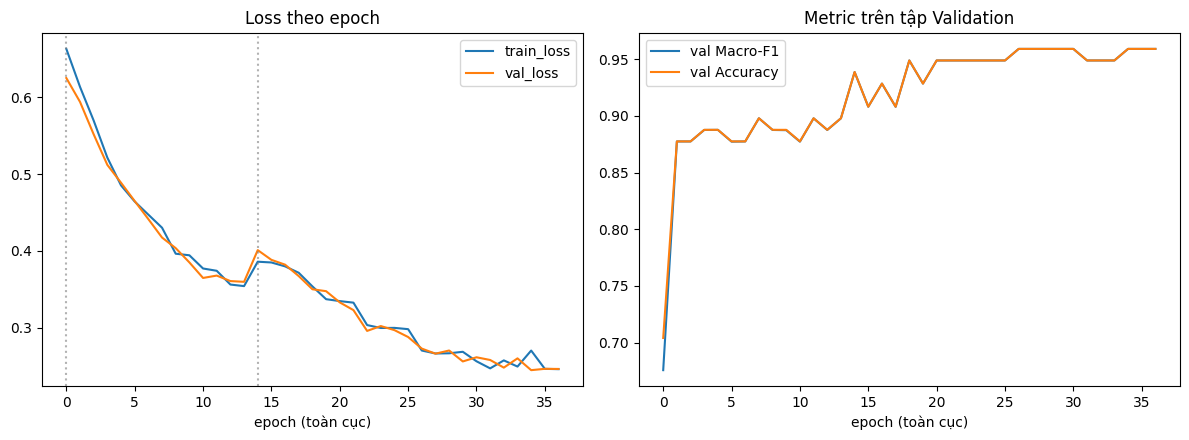

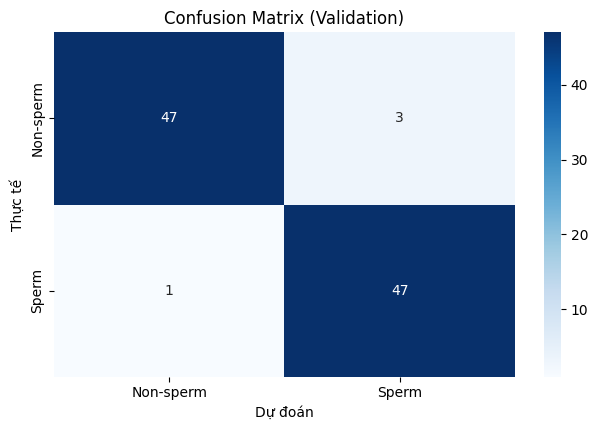

              precision    recall  f1-score   support

   Non-sperm       0.98      0.94      0.96        50
       Sperm       0.94      0.98      0.96        48

    accuracy                           0.96        98
   macro avg       0.96      0.96      0.96        98
weighted avg       0.96      0.96      0.96        98

☁️  Đã lưu toàn bộ output của 'resnet50' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA/resnet50

✅ HOÀN TẤT MODEL 'resnet50'.
   Khi đã train xong toàn bộ model của Task A, hãy mở notebook `Evaluation.ipynb` để đánh giá trên tập TEST.

🚀 BẮT ĐẦU TRAIN MODEL: convnext_base
⚠️  Model 'convnext_base' đã có checkpoint trên Drive:
   /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA/convnext_base/best_model.pth
   Chạy tiếp sẽ GHI ĐÈ kết quả cũ. Đổi MODEL_TO_RUN nếu không muốn ghi đè.


🚀 TRAIN MODEL: convnext_base   (strategy=two_stage)


model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_1781/3740627638.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Epoch 01/15 | train_loss=0.2814 | val_loss=0.0940 | val_acc=0.9796 | val_F1=0.9796 ⭐ | 11.9s
[stage1_head_only] Epoch 02/15 | train_loss=0.0888 | val_loss=0.0634 | val_acc=0.9898 | val_F1=0.9898 ⭐ | 2.9s
[stage1_head_only] Epoch 03/15 | train_loss=0.0665 | val_loss=0.0552 | val_acc=0.9898 | val_F1=0.9898    | 4.4s
[stage1_head_only] Epoch 04/15 | train_loss=0.0641 | val_loss=0.0486 | val_acc=0.9796 | val_F1=0.9796    | 2.8s
[stage1_head_only] Epoch 05/15 | train_loss=0.0473 | val_loss=0.0544 | val_acc=0.9796 | val_F1=0.9796    | 2.8s
[stage1_head_only] Epoch 06/15 | train_loss=0.0458 | val_loss=0.0514 | val_acc=0.9796 | val_F1=0.9796    | 2.8s
[stage1_head_only] Epoch 07/15 | train_loss=0.0366 | val_loss=0.0493 | val_acc=0.9796 | val_F1=0.9796    | 3.4s
[stage1_head_only] Epoch 08/15 | train_loss=0.0303 | val_loss=0.0487 | val_acc=0.9796 | val_F1=0.9796    | 3.7s
  ⏹ Early stopping tại epoch 8 (patience=6)
[stage2_full_finetune] Epoch 01/50 | train_loss=0.0588 | val_

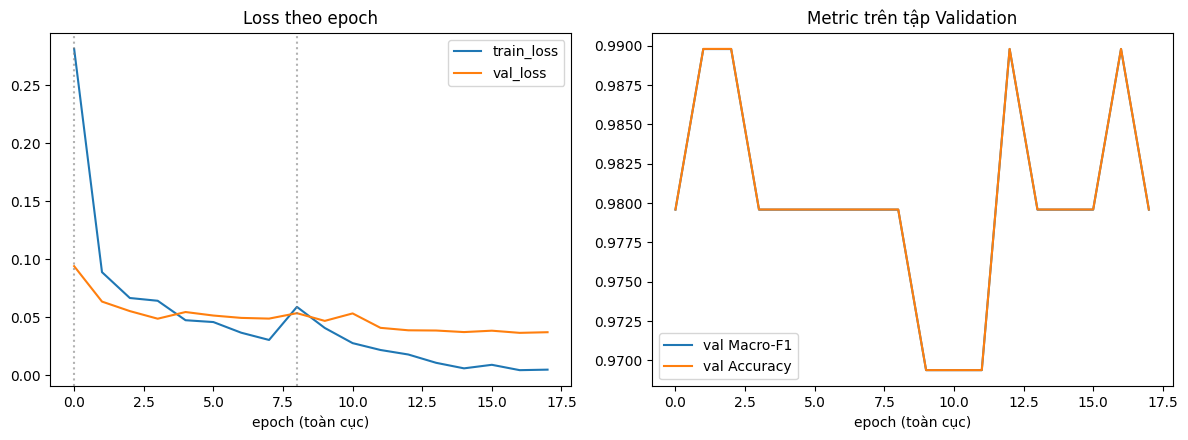

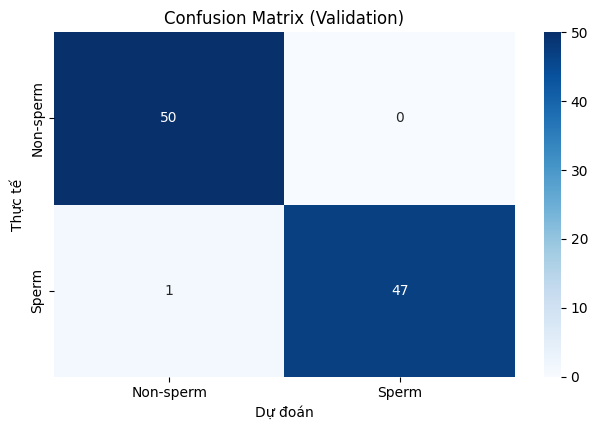

              precision    recall  f1-score   support

   Non-sperm       0.98      1.00      0.99        50
       Sperm       1.00      0.98      0.99        48

    accuracy                           0.99        98
   macro avg       0.99      0.99      0.99        98
weighted avg       0.99      0.99      0.99        98

☁️  Đã lưu toàn bộ output của 'convnext_base' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskA/convnext_base

✅ HOÀN TẤT MODEL 'convnext_base'.
   Khi đã train xong toàn bộ model của Task A, hãy mở notebook `Evaluation.ipynb` để đánh giá trên tập TEST.

🎉 ĐÃ HOÀN TẤT TRAIN TOÀN BỘ MODEL CỦA TASK A.


In [15]:
if __name__ == "__main__":
    # ================= ĐIỀU CHỈNH CÁC THÔNG SỐ NÀY =================
    MODEL_TO_RUN = "ALL"      # "resnet50" | "convnext_base" | "ALL"
    STAGE1_EPOCHS, STAGE1_PATIENCE = 15, 6
    STAGE2_EPOCHS, STAGE2_PATIENCE = 50, 10
    # =================================================================

    if MODEL_TO_RUN == "ALL":
        MODELS_TO_RUN = list(MODEL_CONFIGS.keys())
    else:
        assert MODEL_TO_RUN in MODEL_CONFIGS, f"Model '{MODEL_TO_RUN}' chưa được cấu hình trong MODEL_CONFIGS."
        MODELS_TO_RUN = [MODEL_TO_RUN]

    for MODEL_TO_RUN in MODELS_TO_RUN:

        print("\n" + "=" * 80)
        print(f"🚀 BẮT ĐẦU TRAIN MODEL: {MODEL_TO_RUN}")
        print("=" * 80)

        existing_ckpt = os.path.join(OUTPUT_DRIVE_DIR, MODEL_TO_RUN, "best_model.pth")
        if os.path.exists(existing_ckpt):
            print(f"⚠️  Model '{MODEL_TO_RUN}' đã có checkpoint trên Drive:\n   {existing_ckpt}")
            print("   Chạy tiếp sẽ GHI ĐÈ kết quả cũ. Đổi MODEL_TO_RUN nếu không muốn ghi đè.\n")

        model, history_df, best_val_f1 = train_model(
            model_key=MODEL_TO_RUN,
            num_classes=len(CLASSES),
            class_to_idx=class_to_idx,
            train_list=train_list,
            val_list=val_list,
            stage1_epochs=STAGE1_EPOCHS, stage1_patience=STAGE1_PATIENCE,
            stage2_epochs=STAGE2_EPOCHS, stage2_patience=STAGE2_PATIENCE,
            strategy=MODEL_CONFIGS[MODEL_TO_RUN].get("strategy", "two_stage"),
        )

        val_tf = build_transforms(model, augment=False)
        val_loader_final = DataLoader(SpermDataset(val_list, class_to_idx, val_tf),
                                       batch_size=MODEL_CONFIGS[MODEL_TO_RUN]["batch_size"], shuffle=False)
        val_metrics, val_preds, val_labels = evaluate(model, val_loader_final, nn.CrossEntropyLoss(), device)
        print("\n📊 KẾT QUẢ VALIDATION CUỐI CÙNG:", {k: round(v, 4) for k, v in val_metrics.items()})

        out_dir = save_run_outputs(
            MODEL_TO_RUN, model, history_df, val_metrics, val_preds, val_labels,
            CLASSES, class_to_idx, extra_config={"best_val_f1_macro": best_val_f1}
        )

        print(f"\n✅ HOÀN TẤT MODEL '{MODEL_TO_RUN}'.")
        print("   Khi đã train xong toàn bộ model của Task A, hãy mở notebook `Evaluation.ipynb` để đánh giá trên tập TEST.")

    print("\n" + "=" * 80)
    print("🎉 ĐÃ HOÀN TẤT TRAIN TOÀN BỘ MODEL CỦA TASK A.")
    print("=" * 80)